# A Reproducible Data Workflow on the Pima Indians Diabetes Database

**Author:** Mr Intisar Shah
**Programme:** MSc in Artificial Intelligence (Woolf University)
**Capstone Project 1:** AI Programming Foundations Project

**Dataset:** Pima Indians Diabetes Database - <https://www.kaggle.com/datasets/kumargh/pimaindiansdiabetescsv>

This notebook builds a complete and reproducible data workflow over the Pima Indians Diabetes
Database, a set of 768 diagnostic records for women of Pima heritage aged 21 and over. It loads
the raw CSV, repairs the physiologically impossible zero values that the file uses to encode
missing measurements, explores the cleaned data with reusable functions, and presents three
labelled visualisations of how glucose, BMI and the other variables relate to a diabetes
diagnosis. No model is trained here; the aim is the clean, documented foundation that later
machine learning work can build on.

## 1. Environment and library imports

The workflow uses only NumPy, pandas, Matplotlib and seaborn. Library versions are printed so that
anyone rerunning the notebook can confirm they are working in a comparable environment.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

FIGURE_DIR = "figures"
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("numpy     ", np.__version__)
print("pandas    ", pd.__version__)
print("matplotlib", plt.matplotlib.__version__)
print("seaborn   ", sns.__version__)

numpy      2.3.5
pandas     2.3.3
matplotlib 3.10.6
seaborn    0.13.2


## 2. Data ingestion

The CSV sits in the same folder as this notebook, so it is loaded with a relative path. Printing the
first rows, the shape and the column types confirms the file arrived intact before any cleaning runs.

In [2]:
df_raw = pd.read_csv("diabetes.csv")
df_raw.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
print("Rows, columns:", df_raw.shape)
df_raw.info()

Rows, columns: (768, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


The file holds 768 rows and 9 columns, all numeric, with no blank cells reported by pandas. That last
point is misleading, and section 3 explains why.

### Column reference

| Column | Meaning |
| --- | --- |
| `Pregnancies` | Number of times pregnant |
| `Glucose` | Plasma glucose concentration two hours into an oral glucose tolerance test |
| `BloodPressure` | Diastolic blood pressure (mm Hg) |
| `SkinThickness` | Triceps skin fold thickness (mm) |
| `Insulin` | Two-hour serum insulin (mu U/ml) |
| `BMI` | Body mass index (kg/m2) |
| `DiabetesPedigreeFunction` | Score of diabetes likelihood based on family history |
| `Age` | Age in years (21 to 81) |
| `Outcome` | 1 = diabetes, 0 = no diabetes (target variable) |

## 3. Data cleaning functions

Five columns use `0` to stand in for a measurement that was never taken. A plasma glucose, diastolic
blood pressure, skin fold thickness, serum insulin or BMI of exactly zero is not physiologically
possible in a living patient, so each zero in `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`
and `BMI` is a missing value wearing a plausible number. Zeros in `Pregnancies` are real and stay.

Three functions handle this. Each returns a new DataFrame rather than editing in place, so `df_raw`
survives untouched for comparison.

In [4]:
ZERO_AS_MISSING = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]


def replace_invalid_zeros(df, columns=ZERO_AS_MISSING, verbose=True):
    """Replace physiologically impossible zeros with NaN.

    The source file encodes an unrecorded measurement as 0. A value of zero is
    impossible for plasma glucose, diastolic blood pressure, skin fold thickness,
    serum insulin and BMI, so each zero in those columns is converted to NaN and
    becomes visible to pandas as missing data.

    Args:
        df (pandas.DataFrame): Dataset to clean.
        columns (list of str): Columns in which 0 means "not recorded".
        verbose (bool): When True, print the zero and NaN counts before and after.

    Returns:
        pandas.DataFrame: A copy of df with the invalid zeros replaced by NaN.
    """
    cleaned = df.copy()
    before = pd.DataFrame({
        "zeros_before": (cleaned[columns] == 0).sum(),
        "missing_before": cleaned[columns].isna().sum(),
    })
    cleaned[columns] = cleaned[columns].replace(0, np.nan)
    if verbose:
        report = before.assign(
            zeros_after=(cleaned[columns] == 0).sum(),
            missing_after=cleaned[columns].isna().sum(),
            percent_missing=(cleaned[columns].isna().mean() * 100).round(1),
        )
        print("Impossible zeros converted to NaN:")
        print(report.to_string())
    return cleaned

In [5]:
def impute_missing_with_median(df, columns=ZERO_AS_MISSING, verbose=True):
    """Fill missing values in the given columns with each column's median.

    The median is taken from the observed values of the same column and is applied
    only where a value is missing. It is used instead of the mean because every one
    of these clinical variables is right skewed and carries high outliers, which pull
    a mean upward and would shift the filled values away from the typical patient.

    Args:
        df (pandas.DataFrame): Dataset containing NaN values to fill.
        columns (list of str): Columns to impute.
        verbose (bool): When True, print the median used and the number of values filled.

    Returns:
        pandas.DataFrame: A copy of df with no missing values in columns.
    """
    imputed = df.copy()
    rows = []
    for column in columns:
        median_value = imputed[column].median()
        filled = int(imputed[column].isna().sum())
        imputed[column] = imputed[column].fillna(median_value)
        rows.append({"column": column, "median_used": median_value, "values_filled": filled})
    if verbose:
        print("Median imputation applied:")
        print(pd.DataFrame(rows).to_string(index=False))
        print("\nRemaining missing values:", int(imputed.isna().sum().sum()))
    return imputed

In [6]:
def check_duplicates(df, drop=True, verbose=True):
    """Report duplicate rows and optionally remove them.

    Duplicate patient records would count the same person twice and bias every
    summary statistic and plot that follows, so they are checked for explicitly
    rather than assumed absent.

    Args:
        df (pandas.DataFrame): Dataset to inspect.
        drop (bool): When True, return the data with duplicate rows removed.
        verbose (bool): When True, print how many duplicates were found.

    Returns:
        pandas.DataFrame: A copy of df, deduplicated when drop is True.
    """
    duplicate_count = int(df.duplicated().sum())
    if verbose:
        print(f"Duplicate rows found: {duplicate_count}")
    if drop and duplicate_count:
        return df.drop_duplicates().reset_index(drop=True)
    return df.copy()

### Why the median, and why not drop the rows

Listwise deletion is the obvious alternative, and on this dataset it is the wrong one: 374 of 768
`Insulin` values and 227 `SkinThickness` values are missing, so dropping every incomplete row would
throw away roughly half the file and leave a sample biased toward whichever patients happened to get
the full panel of tests. Median imputation keeps all 768 rows and is robust to the skew and the high
outliers in these clinical variables, at the cost of compressing the spread of the two worst affected
columns. Section 7 and the written report both treat that compression as a limitation rather than a
solved problem.

In [7]:
df_zeros_fixed = replace_invalid_zeros(df_raw)

Impossible zeros converted to NaN:
               zeros_before  missing_before  zeros_after  missing_after  percent_missing
Glucose                   5               0            0              5              0.7
BloodPressure            35               0            0             35              4.6
SkinThickness           227               0            0            227             29.6
Insulin                 374               0            0            374             48.7
BMI                      11               0            0             11              1.4


In [8]:
df_dedup = check_duplicates(df_zeros_fixed)

Duplicate rows found: 0


In [9]:
df_clean = impute_missing_with_median(df_dedup)
print("\nRaw shape:", df_raw.shape, "| Clean shape:", df_clean.shape)
df_clean.head()

Median imputation applied:
       column  median_used  values_filled
      Glucose        117.0              5
BloodPressure         72.0             35
SkinThickness         29.0            227
      Insulin        125.0            374
          BMI         32.3             11

Remaining missing values: 0

Raw shape: (768, 9) | Clean shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,125.0,33.6,0.627,50,1
1,1,85.0,66.0,29.0,125.0,26.6,0.351,31,0
2,8,183.0,64.0,29.0,125.0,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


In [10]:
comparison = pd.DataFrame({
    "raw_mean": df_raw[ZERO_AS_MISSING].mean().round(1),
    "clean_mean": df_clean[ZERO_AS_MISSING].mean().round(1),
    "raw_median": df_raw[ZERO_AS_MISSING].median().round(1),
    "clean_median": df_clean[ZERO_AS_MISSING].median().round(1),
})
print("Effect of cleaning on the five affected columns:")
print(comparison.to_string())

Effect of cleaning on the five affected columns:
               raw_mean  clean_mean  raw_median  clean_median
Glucose           120.9       121.7       117.0         117.0
BloodPressure      69.1        72.4        72.0          72.0
SkinThickness      20.5        29.1        23.0          29.0
Insulin            79.8       140.7        30.5         125.0
BMI                32.0        32.5        32.0          32.3


The raw means for `Insulin`, `SkinThickness` and `BloodPressure` were dragged down by the zeros that
were standing in for missing readings: raw `Insulin` averages about 80 mu U/ml against roughly 140 after
cleaning, because 374 fictional zeros were being averaged in as if they were measurements. This is the
clearest argument for fixing the encoding before any analysis: left alone, those zeros would have
quietly understated every affected variable.

## 4. Exploratory analysis functions

Three functions cover the exploration: an overall summary, a comparison of group means by diagnosis,
and a correlation check against the target.

In [11]:
def summarise_data(df, target="Outcome"):
    """Summarise a dataset's distributions, missing values and class balance.

    Args:
        df (pandas.DataFrame): Dataset to summarise.
        target (str): Name of the binary target column.

    Returns:
        dict: Keys describe, missing and class_balance, each holding the
            corresponding pandas object, so results can be reused downstream.
    """
    description = df.describe().T.round(2)
    missing = pd.DataFrame({
        "missing": df.isna().sum(),
        "percent_missing": (df.isna().mean() * 100).round(1),
    })
    counts = df[target].value_counts().sort_index()
    balance = pd.DataFrame({
        "patients": counts,
        "percent": (counts / len(df) * 100).round(1),
    })
    balance.index = balance.index.map({0: "No diabetes (0)", 1: "Diabetes (1)"})

    print(f"Rows: {len(df)}   Columns: {df.shape[1]}")
    print("\nSummary statistics:")
    print(description.to_string())
    print("\nMissing values:")
    print(missing.to_string())
    print("\nClass balance:")
    print(balance.to_string())
    return {"describe": description, "missing": missing, "class_balance": balance}

In [12]:
def group_by_outcome(df, target="Outcome"):
    """Compare mean values for patients with and without a diabetes diagnosis.

    Args:
        df (pandas.DataFrame): Cleaned dataset.
        target (str): Name of the binary target column.

    Returns:
        pandas.DataFrame: Group means per class, plus the absolute difference and the
            difference as a percentage of the no-diabetes mean, sorted by that percentage.
    """
    grouped = df.groupby(target).mean().T.round(2)
    grouped.columns = ["no_diabetes", "diabetes"]
    grouped["difference"] = (grouped["diabetes"] - grouped["no_diabetes"]).round(2)
    grouped["percent_higher"] = (grouped["difference"] / grouped["no_diabetes"] * 100).round(1)
    grouped = grouped.sort_values("percent_higher", ascending=False)
    print("Mean values by diagnosis:")
    print(grouped.to_string())
    return grouped

In [13]:
def correlation_check(df, target="Outcome", threshold=0.3):
    """Rank how strongly each variable correlates with the target.

    Args:
        df (pandas.DataFrame): Cleaned dataset.
        target (str): Name of the target column.
        threshold (float): Absolute Pearson correlation treated as notable.

    Returns:
        tuple: (correlation_matrix, target_correlations) as pandas objects.
    """
    matrix = df.corr(numeric_only=True).round(2)
    with_target = matrix[target].drop(target).sort_values(key=abs, ascending=False)
    print(f"Pearson correlation with {target}:")
    print(with_target.to_string())
    notable = with_target[with_target.abs() >= threshold]
    if len(notable):
        print(f"\nAt or above |{threshold}|: " + ", ".join(notable.index))
    else:
        print(f"\nNo variable reaches |{threshold}|.")
    return matrix, with_target

In [14]:
summary = summarise_data(df_clean)

Rows: 768   Columns: 9

Summary statistics:
                          count    mean    std    min     25%     50%     75%     max
Pregnancies               768.0    3.85   3.37   0.00    1.00    3.00    6.00   17.00
Glucose                   768.0  121.66  30.44  44.00   99.75  117.00  140.25  199.00
BloodPressure             768.0   72.39  12.10  24.00   64.00   72.00   80.00  122.00
SkinThickness             768.0   29.11   8.79   7.00   25.00   29.00   32.00   99.00
Insulin                   768.0  140.67  86.38  14.00  121.50  125.00  127.25  846.00
BMI                       768.0   32.46   6.88  18.20   27.50   32.30   36.60   67.10
DiabetesPedigreeFunction  768.0    0.47   0.33   0.08    0.24    0.37    0.63    2.42
Age                       768.0   33.24  11.76  21.00   24.00   29.00   41.00   81.00
Outcome                   768.0    0.35   0.48   0.00    0.00    0.00    1.00    1.00

Missing values:
                          missing  percent_missing
Pregnancies                 

The cleaned data has no missing values left, and the two classes are uneven: 500 patients (65.1%) have
no diabetes diagnosis against 268 (34.9%) who do. That imbalance matters for any later model, because a
classifier that predicted "no diabetes" for everyone would already be right 65% of the time.

In [15]:
group_means = group_by_outcome(df_clean)

Mean values by diagnosis:
                          no_diabetes  diabetes  difference  percent_higher
Pregnancies                      3.30      4.87        1.57            47.6
Insulin                        127.79    164.70       36.91            28.9
Glucose                        110.68    142.13       31.45            28.4
DiabetesPedigreeFunction         0.43      0.55        0.12            27.9
Age                             31.19     37.07        5.88            18.9
BMI                             30.89     35.38        4.49            14.5
SkinThickness                   27.73     31.69        3.96            14.3
BloodPressure                   70.92     75.12        4.20             5.9


Every variable is higher on average in the diagnosed group. The proportional gap is widest for
`Pregnancies` (47.6%), then `Insulin` (28.9%) and `Glucose` (28.4%), and glucose is the most
clinically direct of the three: a mean of 142.1 mg/dL in the diagnosed group against 110.7 in the
rest. `BloodPressure` separates the groups least, at a 5.9% gap.

In [16]:
corr_matrix, corr_with_outcome = correlation_check(df_clean)

Pearson correlation with Outcome:
Glucose                     0.49
BMI                         0.31
Age                         0.24
Pregnancies                 0.22
SkinThickness               0.21
Insulin                     0.20
BloodPressure               0.17
DiabetesPedigreeFunction    0.17

At or above |0.3|: Glucose, BMI


Glucose is the strongest single correlate of the diagnosis at about 0.49, followed by BMI and age.
Nothing reaches a correlation that would let one variable stand in for the diagnosis on its own, which
is the expected shape for this kind of clinical screening data.

## 5. Visualisations

Three figures follow, each saved to the `figures/` folder as a PNG so that the written report can
reference the same images. Every figure has a title and labelled axes.

### Figure 1: distribution of plasma glucose by diagnosis

This histogram asks whether the single strongest correlate of the diagnosis actually separates the two
groups, and where along the glucose scale that separation happens.

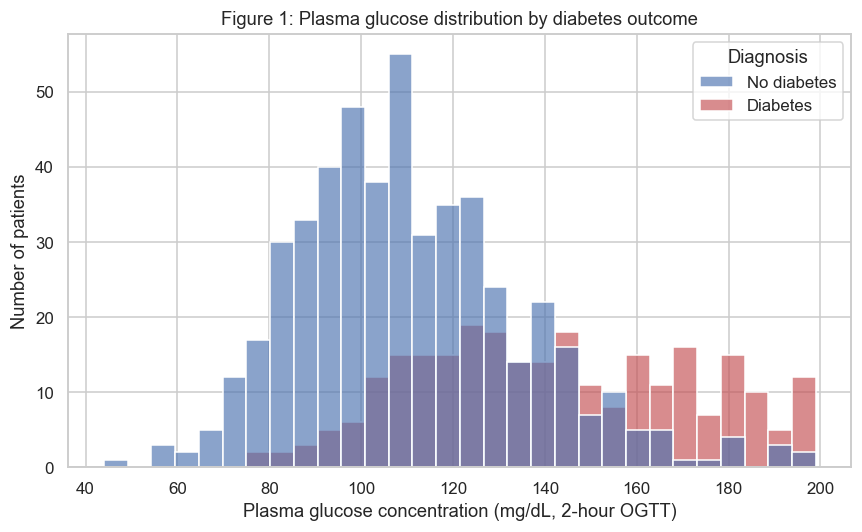

In [17]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(
    data=df_clean,
    x="Glucose",
    hue="Outcome",
    bins=30,
    multiple="layer",
    palette={0: "#4C72B0", 1: "#C44E52"},
    alpha=0.65,
    ax=ax,
)
ax.set_title("Figure 1: Plasma glucose distribution by diabetes outcome")
ax.set_xlabel("Plasma glucose concentration (mg/dL, 2-hour OGTT)")
ax.set_ylabel("Number of patients")
legend = ax.get_legend()
legend.set_title("Diagnosis")
for text, label in zip(legend.get_texts(), ["No diabetes", "Diabetes"]):
    text.set_text(label)
fig.tight_layout()
fig.savefig(f"{FIGURE_DIR}/figure1_glucose_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

The two distributions overlap but sit in different places. Most patients without a diagnosis fall
below 120 mg/dL, 346 of the 500, while the diagnosed group spreads to the right and outnumbers them
above 140 mg/dL by 132 to 60. Glucose separates the groups more clearly than any other single
variable in the file, and the overlap below 140 shows why a diagnosis cannot be read off glucose
alone.

### Figure 2: BMI by diagnosis

A boxplot was chosen here over a second histogram because it puts the medians, the interquartile ranges
and the outliers of the two groups side by side, which is what the comparison needs.

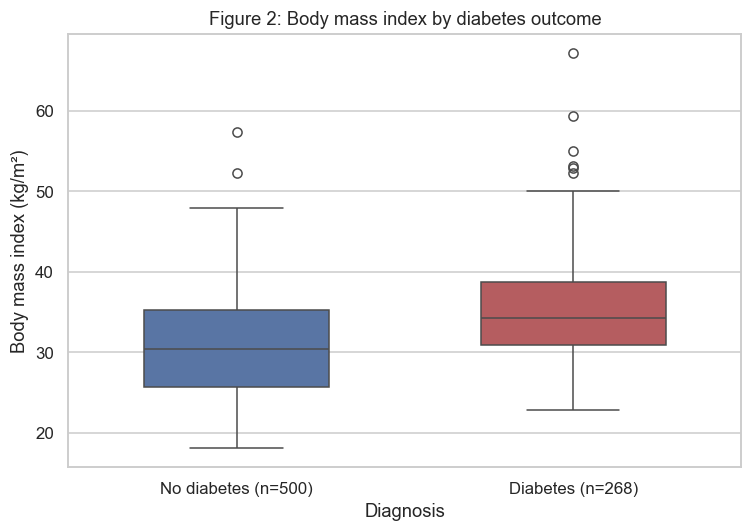

In [18]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(
    data=df_clean,
    x="Outcome",
    y="BMI",
    hue="Outcome",
    palette={0: "#4C72B0", 1: "#C44E52"},
    legend=False,
    width=0.55,
    ax=ax,
)
ax.set_title("Figure 2: Body mass index by diabetes outcome")
ax.set_xlabel("Diagnosis")
ax.set_ylabel("Body mass index (kg/m²)")
ax.set_xticks([0, 1])
ax.set_xticklabels(["No diabetes (n=500)", "Diabetes (n=268)"])
fig.tight_layout()
fig.savefig(f"{FIGURE_DIR}/figure2_bmi_by_outcome.png", dpi=150, bbox_inches="tight")
plt.show()

The diagnosed group has a higher median BMI, 34.3 against 30.4, and its box sits higher overall.
Both groups fall in the overweight-to-obese range on the standard BMI scale, so BMI shifts the odds
rather than splitting the sample, and the boxes overlap across most of their range. Both groups also
carry high outliers above 50.

### Figure 3: correlation heatmap

The heatmap gives the whole correlation structure at once, which is what matters before any modelling:
which variables track the outcome, and which track each other closely enough to be partly redundant.

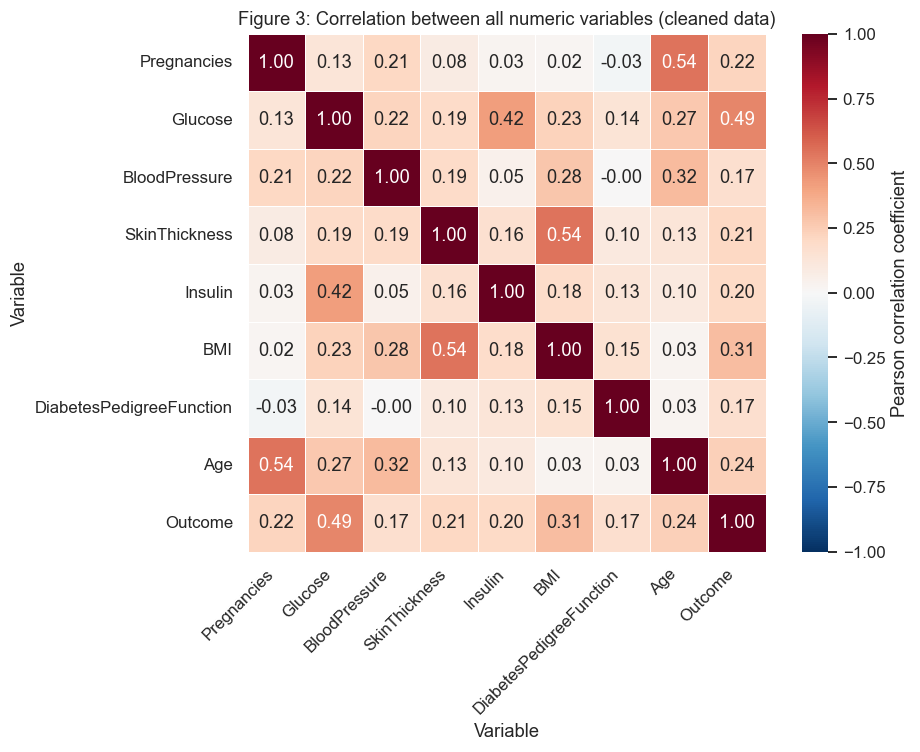

In [19]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Pearson correlation coefficient"},
    ax=ax,
)
ax.set_title("Figure 3: Correlation between all numeric variables (cleaned data)")
ax.set_xlabel("Variable")
ax.set_ylabel("Variable")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
fig.tight_layout()
fig.savefig(f"{FIGURE_DIR}/figure3_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

Reading the `Outcome` row, glucose (0.49), BMI (0.31) and age (0.24) are the strongest links to the
diagnosis. Two pairs stand out away from the target: age with pregnancies (0.54), and insulin with
glucose (0.42). `SkinThickness` and `BMI` correlate at 0.54 as well, which is expected since both
measure body fat. Those pairs carry overlapping information, so a later model would not gain much from
treating them as independent inputs.

## 6. Reusing the workflow

The cleaning and exploration steps are plain functions, so the whole workflow runs on a fresh copy of
the file in four calls. This is what makes it reusable rather than a one-off script.

In [20]:
def run_workflow(csv_path="diabetes.csv", verbose=False):
    """Run the full ingest, clean and summarise workflow on a CSV file.

    Args:
        csv_path (str): Path to the raw dataset.
        verbose (bool): When True, print each step's diagnostic output.

    Returns:
        pandas.DataFrame: The cleaned dataset.
    """
    data = pd.read_csv(csv_path)
    data = replace_invalid_zeros(data, verbose=verbose)
    data = check_duplicates(data, verbose=verbose)
    data = impute_missing_with_median(data, verbose=verbose)
    return data


rerun = run_workflow()
print("Reran workflow from file:", rerun.shape)
print("Matches the cleaned data built above:", rerun.equals(df_clean))

Reran workflow from file: (768, 9)
Matches the cleaned data built above: True


## 7. Summary and interpretation

The main lesson from this dataset is that a file can be complete and still be full of missing data.
Pandas reported no null values in all 768 rows, yet 374 `Insulin` readings, 227 `SkinThickness`
readings, 35 `BloodPressure` readings, 11 `BMI` readings and 5 `Glucose` readings were stored as zeros
that no living patient could have. Had I trusted the null count, the mean insulin level would have come
out near 80 mu U/ml instead of roughly 140, and every figure built on it would have been wrong in the
same direction.

The patterns in the cleaned data are consistent and clinically unsurprising. Plasma glucose separates
the two groups most clearly (Figure 1) and is the strongest correlate of the diagnosis at 0.49
(Figure 3), with BMI at 0.31 and age at 0.24 behind it. Patients with a diagnosis have a higher median
BMI, 34.3 against 30.4 (Figure 2), and higher means on every variable in the file. What surprised me
was how modest those correlations are: no single measurement comes close to determining the outcome,
and the distributions overlap heavily, so the signal here is genuinely multivariate. The number of
pregnancies showed the largest proportional gap between the groups, which reflects both age and the
gestational diabetes history specific to this cohort rather than a general risk factor.

Three assumptions and limitations carry through everything above. First, I assumed every zero in those
five columns is a missing measurement rather than a recording error of another kind; the clinical
impossibility of the values makes this safe, but it is still an inference about how the file was
produced. Second, median imputation keeps all 768 rows at the cost of compressing the spread of the two
worst affected columns: with 48.7% of `Insulin` and 29.6% of `SkinThickness` values filled from a single
number each, both distributions now have an artificial spike at the median, and any correlation
involving them should be read as a floor rather than an estimate. Third, the cohort is women of Pima
heritage aged 21 and over, so nothing here generalises to men, to younger patients, or to other
populations. The 65/35 class imbalance is worth carrying forward too, since it sets the baseline any
future classifier has to beat.

One thing remains unclear from the data alone. `DiabetesPedigreeFunction` is documented only as a score
of diabetes likelihood based on family history, without the formula behind it, so its weak correlation
with the outcome (0.17) cannot be interpreted properly: a weak genuine signal and a poorly constructed
score would look the same here.